# 02 — Da seleção fotométrica à validação espectroscópica

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** depois de selecionar candidatos em um catálogo, quais deles possuem informação espectroscópica independente?

O exemplo usa uma tabela local de alvos e faz o crossmatch no servidor com DESI DR1. Isso evita baixar um catálogo espectroscópico inteiro apenas para cruzá-lo localmente.
`upload.targets` é a tabela temporária enviada em `file=targets`. `cone` compara posições em graus; `dist` mede a separação angular para examinar a qualidade da associação.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import adss

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

In [2]:
# Use a saída do notebook anterior ou substitua por sua própria lista de alvos.
# Exemplo mínimo para permitir execução independente:
targets = pd.read_csv("outputs/cluster_1.csv")

In [3]:
targets

,source_id,ra,dec,radius_deg,pmra,pmdec,pmra_error,pmdec_error,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe,kinematic_excess
0,2686840521431628288,323.324139,-0.880722,0.069110,3.535957,-2.173133,0.114538,0.073543,0.008011,0.113313,17.320658,17.716633,16.747751,0.968882,0.979177,2.002077
1,2686842033259327104,323.216615,-0.902025,0.165845,3.540397,-2.169961,0.119509,0.083477,-0.033886,0.115138,17.649788,18.056982,17.079865,0.977118,1.053021,2.002068
2,2686841208630066176,323.323723,-0.850133,0.047235,3.523109,-2.172632,0.082432,0.045770,-0.009831,0.066133,16.312115,16.360470,16.273584,0.086885,1.005163,2.002033
3,2686843579447556992,323.253369,-0.887782,0.126833,3.523987,-2.174720,0.123127,0.080571,0.130173,0.114084,17.476366,17.879677,16.900747,0.978930,1.036951,2.002006
4,2686850245241277696,323.344394,-0.804620,0.026083,3.551845,-2.166595,0.198749,0.100412,0.172955,0.130352,17.393589,17.130636,16.252893,0.877743,1.163365,2.001873
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,2686844266646783872,323.328537,-0.826074,0.034172,3.608585,-2.083400,0.051430,0.030223,-0.021024,0.043483,15.561186,15.965014,14.886327,1.078688,0.935104,1.984347
354,2686846950998135552,323.372174,-0.839668,0.018962,3.343826,-2.173708,0.085897,0.042853,-0.241768,0.059241,16.045662,15.896893,15.394764,0.502129,1.094846,1.984327
355,2686846946706465792,323.383652,-0.838759,0.026117,3.350035,-2.112683,0.082595,0.038944,-0.121880,0.050212,15.921176,15.863598,15.545351,0.318247,0.917976,1.984300
356,2686890343051497344,323.139072,-0.840369,0.224155,3.366053,-2.096690,0.108775,0.088214,0.111751,0.103947,17.169144,17.575636,16.587310,0.988325,1.030786,1.984230


### Consulta de redshifts DESI

Associe `upload.targets` a `desi.desi_specz_dr1` por posição dentro de **0,0003°**. Retorne o ID Gaia de entrada, as duas posições, ID DESI, `z`, `zerr`, `zwarn`, `spectype`, `subtype`, `deltachi2` e a separação em graus. Use os aliases esperados pelo código (`input_source_id`, `desi_id`, `desi_ra`, `desi_dec`, `separation_deg`).


In [ ]:
query = None  # Complete a consulta AstroQL do enunciado.
if query is None:
    raise NotImplementedError("Complete query; veja outputs/respostas.txt após tentar.")

spec = cl.query_and_wait(
    query_text=query,
    mode="astroql",
    file=targets,
    table_name="targets",
).data
spec.head()

spectype
STAR    20
Name: count, dtype: int64


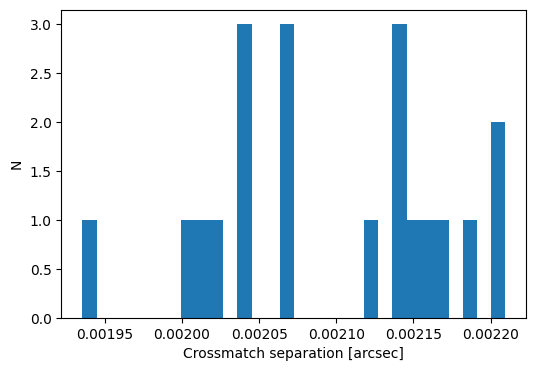

In [5]:
spec["separation_arcsec"] = spec.separation_deg * 3600
print(spec.spectype.value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(spec.separation_arcsec.dropna(), bins=30)
ax.set(xlabel="Crossmatch separation [arcsec]", ylabel="N")
plt.show()

### Espectros DESI dos objetos associados

O catálogo `desi.desi_specz_dr1` fornece a classificação e o redshift. Os arrays espectrais estão em `desi.desi_dr1`, ligados por `desi_id = targetid`. Consultamos apenas os IDs encontrados acima e incluímos as três câmeras (B, R e Z).

`wave_*` contém comprimentos de onda, `flux_*` o fluxo espectral e `ivar_*` a **variância inversa** em cada pixel. Um pixel com `ivar <= 0` não tem peso útil no gráfico. As bandas B/R/Z são braços do espectrógrafo, não filtros fotométricos.

Agora associe os IDs únicos de `upload.desitargets` a `desi.desi_dr1` por `desi_id = targetid`. Selecione `wave`, `flux` e `ivar` para B, R e Z, além do ID. O nome da tabela carregada no ADSS deve coincidir com `table_name="desitargets"`.


In [ ]:
# Fetch one spectral row per matched DESI target, including all three arms.
desi_targets = spec[["desi_id", "desi_ra", "desi_dec"]].dropna().drop_duplicates().astype("int64")

if desi_targets.empty:
    spectra = pd.DataFrame(columns=["desi_id"] + [
        f"{quantity}_{arm}"
        for arm in ("b", "r", "z")
        for quantity in ("wave", "flux", "ivar")
    ])
else:
    spectra_query = None  # Complete a consulta AstroQL do enunciado.
    if spectra_query is None:
        raise NotImplementedError("Complete spectra_query; veja outputs/respostas.txt após tentar.")
    spectra = cl.query_and_wait(
        query_text=spectra_query,
        mode="astroql",
        file=desi_targets,
        table_name="desitargets",
    ).data

print(f"Matched DESI IDs: {len(desi_targets)}; spectra returned: {len(spectra)}")


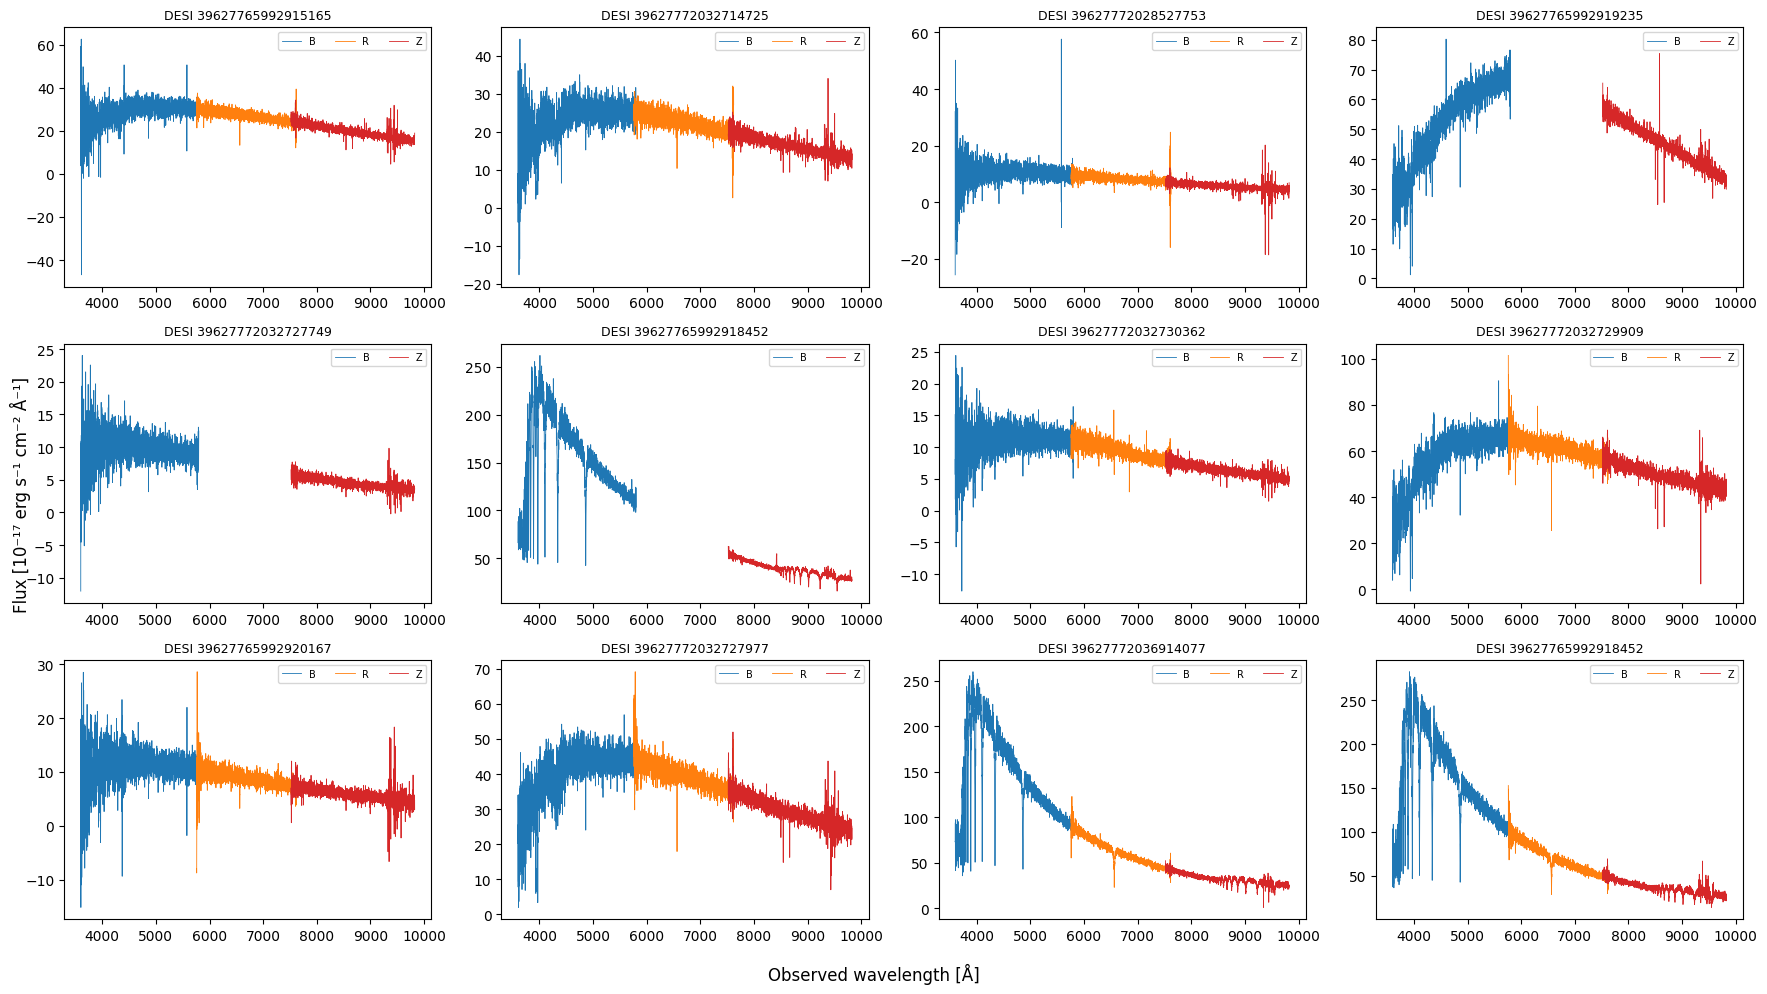

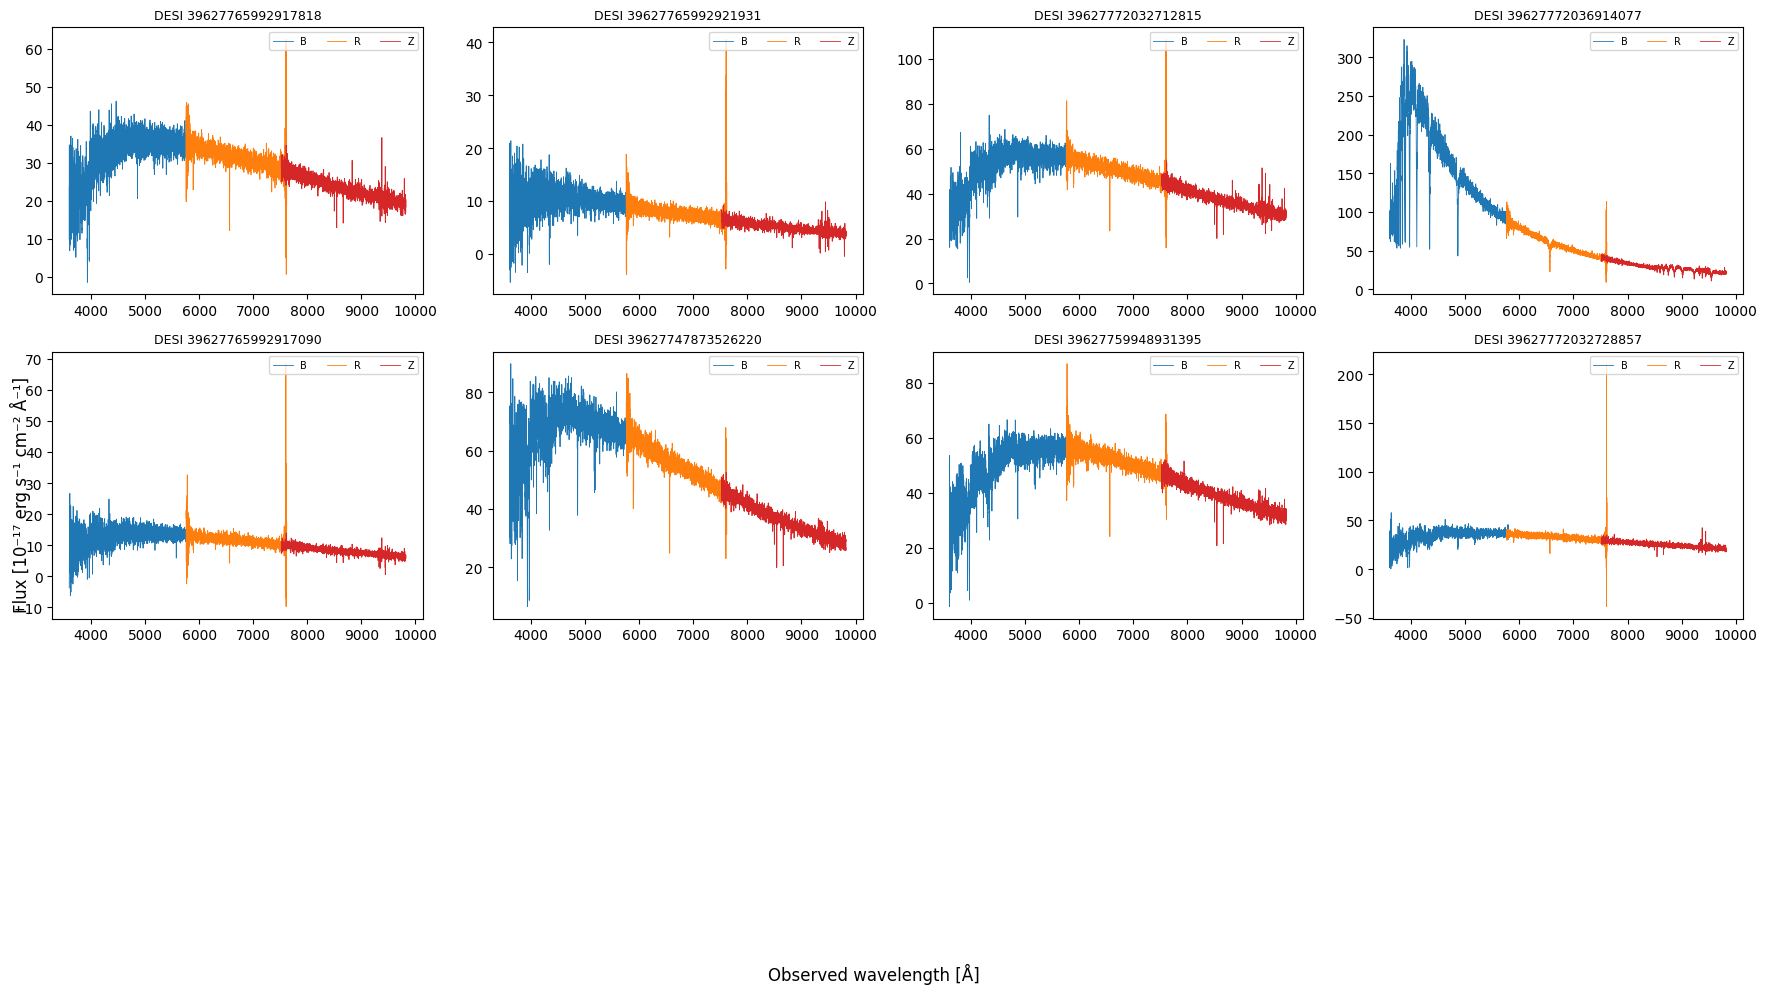

Plotted 20 of 20 returned spectra


In [16]:
# Plot every returned spectrum, with the B/R/Z arms in separate colors.
arms = {"b": "tab:blue", "r": "tab:orange", "z": "tab:red"}
page_size = 12
plotted = 0

for start in range(0, len(spectra), page_size):
    page = spectra.iloc[start:start + page_size]
    fig, axes = plt.subplots(3, 4, figsize=(18, 10), squeeze=False)
    for ax, (_, row) in zip(axes.flat, page.iterrows()):
        n_arms = 0
        for arm, color in arms.items():
            wave_values = row[f"wave_{arm}"]
            flux_values = row[f"flux_{arm}"]
            ivar_values = row[f"ivar_{arm}"]
            if any(value is None for value in (wave_values, flux_values, ivar_values)):
                continue
            wave = np.asarray(wave_values, dtype=float)
            flux = np.asarray(flux_values, dtype=float)
            ivar = np.asarray(ivar_values, dtype=float)
            if wave.ndim != 1 or wave.shape != flux.shape or wave.shape != ivar.shape:
                continue
            valid = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
            if valid.any():
                ax.plot(wave[valid], flux[valid], color=color, lw=0.6, label=arm.upper())
                n_arms += 1
        ax.set_title(f"DESI {row.desi_id}", fontsize=9)
        if n_arms:
            ax.legend(fontsize=7, ncol=3, loc="upper right")
            plotted += 1
        else:
            ax.text(0.5, 0.5, "No valid samples", ha="center", va="center",
                    transform=ax.transAxes)
    for ax in axes.flat[len(page):]:
        ax.set_visible(False)
    fig.supxlabel("Observed wavelength [Å]")
    fig.supylabel("Flux [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
    fig.tight_layout()
    plt.show()

print(f"Plotted {plotted} of {len(spectra)} returned spectra")


### Investigação
Compare a classificação/seleção original dos alvos com `spectype`, `z`, `zwarn` e `deltachi2`. Em um projeto real, este passo pode transformar um conjunto de candidatos puramente fotométricos em uma amostra de validação independente.